**CS 4140 – Deep Learning · L14 · Transfer learning and fine-tuning** &nbsp; [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Bolufe-Rohler/4140-deep-learning/blob/main/lectures/L14_transfer-learning/L14_transfer_learning.ipynb)

Run the first code cell before anything else. In Colab, *File → Save a copy in Drive* keeps your own changes.

In [ ]:
# ▶ Run this cell first. It gets the course code and this lecture's saved results and data,
#   in Google Colab or on your own computer.
LECTURE = "L14_transfer-learning"
REPO = "https://github.com/Bolufe-Rohler/4140-deep-learning"
import os, sys, subprocess
root = os.path.abspath(os.path.join("..", ".."))
if not os.path.isfile(os.path.join(root, "cs4140_setup.py")):  # not inside the course repo (e.g. Colab)
    root = "/content/cs4140" if "google.colab" in sys.modules else os.path.abspath("cs4140")
    if not os.path.isdir(root):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", REPO, root], check=True)
    os.chdir(os.path.join(root, "lectures", LECTURE))
sys.path.insert(0, root)
import cs4140_setup
cs4140_setup.fetch_assets(LECTURE)

# CS 4140 · Lecture 14 · Transfer Learning and Fine-Tuning

**Can a network trained on ImageNet spot potato blight?** The saved runs behind the slides.

| Part | Question |
|---|---|
| 1 | What does a pretrained ResNet-18 "see" in potato leaves, before any training on them? |
| 2 | Frozen features, fine-tuning or training from scratch: which wins, and how does it depend on the number of photos? |
| 3 | A model trained on lab photos meets field photos: domain shift, and what a few field photos fix |
| 4 | Choosing a backbone: ResNet-18, ResNet-50, MobileNetV3, EfficientNet-B0 (size, speed, accuracy, and where the 1×1 convolutions are) |

**Data** (in `data/`, see `data/CREDITS.md`)

* **Lab photos:** the potato part of PlantVillage: 1,000 early blight, 1,000 late blight and 152 healthy leaves photographed on a plain background. Every leaf was photographed 4 times, so train and test are split **by leaf** (`leaf` column of `data/lab_index.csv`), never by photo.
* **Field photos:** the potato part of PlantDoc: 117 early blight and 105 late blight leaves photographed in fields and gardens (no healthy potato class).

**Two ways to run it**

* `CLASS_MODE = True` (default): loads the saved runs from `results/` and redraws every figure. Only missing runs are trained. With the saved runs this takes under a minute on a laptop CPU and needs no internet.
* `CLASS_MODE = False`: retrains everything, about 30–40 minutes on a 2-core CPU. Each run is saved when it finishes, so an interrupted run can be completed in class mode.

In [1]:
CLASS_MODE = True

import os, json, math, time, csv, random, copy
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import models
from torchvision.transforms import v2 as T
from PIL import Image
import matplotlib, matplotlib.pyplot as plt
from matplotlib import font_manager

torch.set_num_threads(max(1, os.cpu_count() or 1))
DATA, RESULTS, FIGS = 'data', 'results', 'figures'
LAYERS = os.path.join(FIGS, 'layers')
for d in (RESULTS, FIGS, LAYERS): os.makedirs(d, exist_ok=True)

for f in font_manager.findSystemFonts():
    if 'schola' in f.lower() or 'century schoolbook' in f.lower() or 'centsch' in f.lower():
        font_manager.fontManager.addfont(f)
names = {f.name for f in font_manager.fontManager.ttflist}
SERIF = next((n for n in ['Century Schoolbook', 'TeX Gyre Schola', 'DejaVu Serif'] if n in names), 'serif')
plt.rcParams.update({'font.family': SERIF, 'font.size': 15, 'axes.titlesize': 17, 'axes.labelsize': 16,
                     'legend.fontsize': 14, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.dpi': 110, 'savefig.dpi': 200, 'mathtext.fontset': 'dejavuserif'})
BLUE, RED, GREY, NAVY, GREEN, ORANGE = '#1A1AFF', '#C00000', '#8C8C8C', '#000080', '#2E8B57', '#D9822B'
CLASSES = ['healthy', 'early_blight', 'late_blight']
NICE = {'healthy': 'healthy', 'early_blight': 'early blight', 'late_blight': 'late blight'}
CCOL = {'healthy': GREEN, 'early_blight': ORANGE, 'late_blight': RED}

def save(fig, name):
    fig.savefig(os.path.join(FIGS, name + '.png'), bbox_inches='tight', facecolor='white')

def save_layers(fig, name, groups, hide=None):
    """One full image per click (same size, so they stack exactly on a slide)."""
    hide = hide or {}
    fig.canvas.draw()
    box = fig.get_tightbbox(fig.canvas.get_renderer()).padded(0.08)
    for g in groups:
        for a in g: a.set_visible(False)
    for k, g in enumerate(groups, 1):
        for a in g: a.set_visible(True)
        for a in hide.get(k, []): a.set_visible(False)
        fig.savefig(os.path.join(LAYERS, f'{name}_{k}.png'), facecolor='white', bbox_inches=box)
    fig.savefig(os.path.join(FIGS, name + '.png'), facecolor='white', bbox_inches=box)

RES_FILE = os.path.join(RESULTS, 'results.json')
R = json.load(open(RES_FILE)) if os.path.exists(RES_FILE) else {}
def store(): json.dump(R, open(RES_FILE, 'w'), indent=1)

In [2]:
# ---------------------------------------------------------------- data and leaf-based splits
lab = list(csv.DictReader(open(os.path.join(DATA, 'lab_index.csv'))))
field = list(csv.DictReader(open(os.path.join(DATA, 'field_index.csv'))))
y_lab = np.array([CLASSES.index(r['label']) for r in lab])
y_field = np.array([CLASSES.index(r['label']) for r in field])

rng = np.random.default_rng(2027)
TEST_LEAVES_PER_CLASS = 13                     # 13 leaves x 4 photos = 52 test photos per class
test_idx, pool = [], {}
for c in CLASSES:
    leaves = sorted({r['leaf'] for r in lab if r['label'] == c})
    rng.shuffle(leaves)
    test_leaves, pool[c] = set(leaves[:TEST_LEAVES_PER_CLASS]), leaves[TEST_LEAVES_PER_CLASS:]
    test_idx += [i for i, r in enumerate(lab) if r['leaf'] in test_leaves]
test_idx = np.array(sorted(test_idx))

def train_indices(n_leaves, seed):
    """n_leaves leaves per class (4 photos each), drawn from the training pool."""
    g = np.random.default_rng(seed)
    idx = []
    for c in CLASSES:
        chosen = set(g.choice(pool[c], size=n_leaves, replace=False))
        idx += [i for i, r in enumerate(lab) if r['leaf'] in chosen]
    return np.array(sorted(idx))

# field photos: 20 per disease may be used for training (Part 3), the rest is the field test set
g = np.random.default_rng(7)
field_train, field_test = [], []
for c in ['early_blight', 'late_blight']:
    ids = [i for i, r in enumerate(field) if r['label'] == c]
    g.shuffle(ids); field_train += ids[:20]; field_test += ids[20:]
field_train, field_test = np.array(sorted(field_train)), np.array(sorted(field_test))

print('lab photos:', {c: int((y_lab == k).sum()) for k, c in enumerate(CLASSES)},
      '| leaves in the training pool:', {c: len(pool[c]) for c in CLASSES})
print('lab test photos:', len(test_idx), '| field photos:', len(field), f'({len(field_train)} for training, {len(field_test)} for testing)')

lab photos: {'healthy': 152, 'early_blight': 1000, 'late_blight': 1000} | leaves in the training pool: {'healthy': 25, 'early_blight': 237, 'late_blight': 237}
lab test photos: 156 | field photos: 222 (40 for training, 182 for testing)


In [3]:
# ---------------------------------------------------------------- images as tensors (160 x 160 crops keep the CPU runs short)
MEAN, STD = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1), torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def load_all(rows, size):
    tf = T.Compose([T.Resize(size), T.CenterCrop(size), T.PILToTensor()])
    return torch.stack([tf(Image.open(os.path.join(DATA, r['path'])).convert('RGB')) for r in rows])   # uint8

t0 = time.time()
LAB182, FIELD182 = load_all(lab, 182), load_all(field, 182)
print(f'decoded {len(lab) + len(field)} photos in {time.time() - t0:.0f}s', tuple(LAB182.shape))

def to_input(u8):                       # uint8 batch -> normalized float batch (ImageNet statistics)
    return (u8.float() / 255 - MEAN) / STD

def center(u8, size=160):
    o = (u8.shape[-1] - size) // 2
    return u8[..., o:o + size, o:o + size]

augment = T.Compose([T.RandomResizedCrop(160, scale=(0.6, 1.0), antialias=True),
                     T.RandomHorizontalFlip(), T.RandomVerticalFlip()])

decoded 2374 photos in 6s (2152, 3, 182, 182)


## Part 1 · What a pretrained ResNet-18 sees, before any training on potatoes

Remove the last layer of an ImageNet ResNet-18: every photo becomes a vector of 512 numbers (Feb 22). We squash the 512 numbers to 2 with PCA, only to look at them.

lab features (2152, 512) | field features (222, 512)


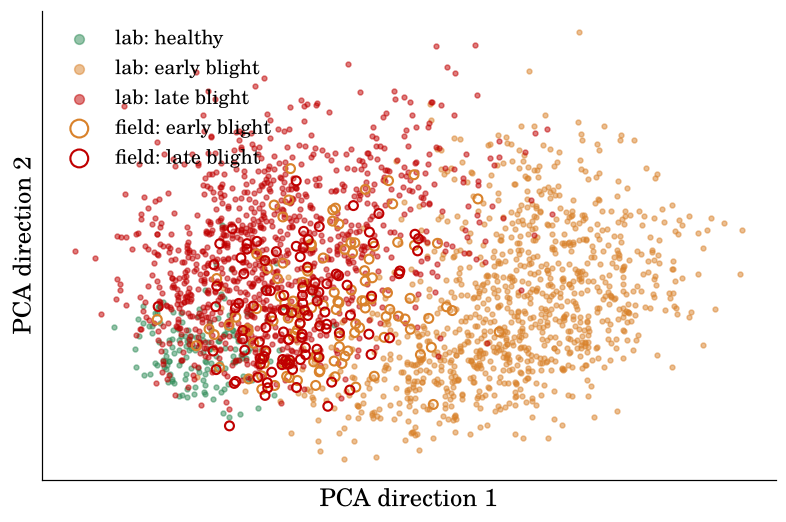

In [4]:
def resnet18(pretrained=True, n_out=3):
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    m.fc = nn.Linear(512, n_out)              # replace the 1000-class head by a 3-class head
    return m

@torch.no_grad()
def features(backbone, u8, size=None, bs=64):
    backbone.eval(); out = []
    for i in range(0, len(u8), bs):
        x = u8[i:i + bs]
        if size: x = center(x, size)
        out.append(backbone(to_input(x)))
    return torch.cat(out)

FEAT_FILE = os.path.join(RESULTS, 'resnet18_features_160.pt')
if os.path.exists(FEAT_FILE):                                 # saved: no download needed
    Fl, Ff = torch.load(FEAT_FILE)
else:
    fx = resnet18(); fx.fc = nn.Identity()                    # the frozen feature extractor
    t0 = time.time(); Fl, Ff = features(fx, LAB182, 160), features(fx, FIELD182, 160)
    torch.save((Fl, Ff), FEAT_FILE); print(f'features in {time.time() - t0:.0f}s')
print('lab features', tuple(Fl.shape), '| field features', tuple(Ff.shape))

# PCA fitted on the lab photos only
mu = Fl.mean(0); U, S, V = torch.pca_lowrank(Fl - mu, q=2, center=False)
Pl, Pf = ((Fl - mu) @ V).numpy(), ((Ff - mu) @ V).numpy()
fig, ax = plt.subplots(figsize=(7.4, 5.0))
arts = [[], []]
for k, c in enumerate(CLASSES):
    s = ax.scatter(*Pl[y_lab == k].T, s=10, color=CCOL[c], alpha=0.5, label=f'lab: {NICE[c]}')
    arts[0].append(s)
for k, c in enumerate(CLASSES[1:], 1):
    s = ax.scatter(*Pf[y_field == k].T, s=34, facecolors='none', edgecolors=CCOL[c], lw=1.4, label=f'field: {NICE[c]}')
    arts[1].append(s)
ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel('PCA direction 1'); ax.set_ylabel('PCA direction 2')
leg1 = ax.legend(handles=arts[0], loc='upper left', frameon=False, fontsize=13, markerscale=2)
ax.add_artist(leg1)
leg2 = ax.legend(handles=arts[0] + arts[1], loc='upper left', frameon=False, fontsize=13, markerscale=2)
arts[0].append(leg1); arts[1].append(leg2)
fig.tight_layout()
save_layers(fig, 'fig_pca', arts, hide={2: [leg1]})
plt.show()

## Part 2 · Frozen features vs fine-tuning vs training from scratch

The same ResNet-18 architecture, three ways, trained on 1, 5 or 25 leaves per class (4, 20 or 100 photos per class):

* **frozen:** keep the ImageNet weights, train only a new 3-class layer on the 512 features
* **fine-tune:** start from the ImageNet weights and update all of them (learning rate 0.01, 100 steps of 16 photos, flips and random crops)
* **scratch:** random initial weights, same recipe, 300 steps

Test: 156 photos of 39 other leaves (13 per class). Seeds 0–2 for 1 and 5 leaves, seed 0 for 25 leaves (to keep the CPU time down).

In [5]:
def train_head(Xtr, ytr, steps=300, wd=1e-3, seed=0):
    torch.manual_seed(seed)
    mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6
    head = nn.Linear(Xtr.shape[1], 3)
    opt = torch.optim.Adam(head.parameters(), lr=1e-2, weight_decay=wd)
    for _ in range(steps):
        loss = F.cross_entropy(head((Xtr - mu) / sd), ytr); opt.zero_grad(); loss.backward(); opt.step()
    return lambda X: head((X - mu) / sd).detach()

def train_cnn(model, idx_lab, idx_field=(), steps=100, lr=0.01, bs=16, seed=0):
    torch.manual_seed(seed); g = torch.Generator().manual_seed(seed)
    X = torch.cat([LAB182[idx_lab], FIELD182[list(idx_field)]]) if len(idx_field) else LAB182[idx_lab]
    y = torch.tensor(np.concatenate([y_lab[idx_lab], y_field[list(idx_field)]]) if len(idx_field) else y_lab[idx_lab])
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.15)
    model.train()
    for s in range(steps):
        b = torch.randint(0, len(X), (min(bs, len(X)),), generator=g)
        xb = torch.stack([augment(x) for x in X[b]])
        loss = F.cross_entropy(model(to_input(xb)), y[b])
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    model.eval()
    return lambda u8: features(model, u8, 160)          # model outputs = logits

def scores(predict_lab, predict_field):
    """lab: 3-class accuracy on the lab test photos; field: early vs late blight on the field test photos."""
    lab_acc = float((predict_lab.argmax(1) == torch.tensor(y_lab[test_idx])).float().mean())
    pf = predict_field[:, 1:].argmax(1) + 1              # decide only between the two diseases
    field_acc = float((pf == torch.tensor(y_field[field_test])).float().mean())
    said_healthy = float((predict_field.argmax(1) == 0).float().mean())
    return {'lab': lab_acc, 'field': field_acc, 'field_said_healthy': said_healthy}

R.setdefault('size_runs', {})
PLAN = [(n, s) for n in (1, 5) for s in (0, 1, 2)] + [(25, 0)]
for method in ['frozen', 'finetune', 'scratch']:
    for n, seed in PLAN + ([(25, 1), (25, 2)] if method == 'frozen' else []):
        key = f'{method}|{n}|{seed}'
        if key in R['size_runs'] and CLASS_MODE: continue      # class mode: keep the saved run
        idx = train_indices(n, seed); t0 = time.time()
        if method == 'frozen':
            pred = train_head(Fl[idx], torch.tensor(y_lab[idx]), seed=seed)
            res = scores(pred(Fl[test_idx]), pred(Ff[field_test]))
        else:
            m = resnet18(pretrained=(method == 'finetune'))
            pred = train_cnn(m, idx, steps=100 if method == 'finetune' else 300, lr=0.01 if method == 'finetune' else 0.05, seed=seed)
            res = scores(pred(LAB182[test_idx]), pred(FIELD182[field_test]))
            if n == 25 and seed == 0:
                torch.save({k: v.half() if v.is_floating_point() else v for k, v in m.state_dict().items()},   # float16: half the size
                           os.path.join(RESULTS, f'{method}_25leaves.pt'))
        res['seconds'] = time.time() - t0
        R['size_runs'][key] = res; store()
        print(f'{key:16s} lab {res["lab"]:.1%}  field {res["field"]:.1%}  ({res["seconds"]:.0f}s)')

def summary(method, n, metric='lab'):
    v = [r[metric] for k, r in R['size_runs'].items() if k.startswith(f'{method}|{n}|')]
    return 100 * np.mean(v), 100 * np.min(v), 100 * np.max(v), len(v)
for method in ['frozen', 'finetune', 'scratch']:
    print(method, ' | '.join(f'{n} leaves: {summary(method, n)[0]:.1f}% (min {summary(method, n)[1]:.1f}, n={summary(method, n)[3]})' for n in (1, 5, 25)))

frozen 1 leaves: 75.0% (min 67.9, n=3) | 5 leaves: 87.8% (min 85.9, n=3) | 25 leaves: 95.7% (min 94.9, n=3)
finetune 1 leaves: 73.3% (min 67.3, n=3) | 5 leaves: 94.2% (min 91.7, n=3) | 25 leaves: 96.8% (min 96.8, n=1)
scratch 1 leaves: 62.8% (min 56.4, n=3) | 5 leaves: 84.4% (min 80.8, n=3) | 25 leaves: 87.8% (min 87.8, n=1)


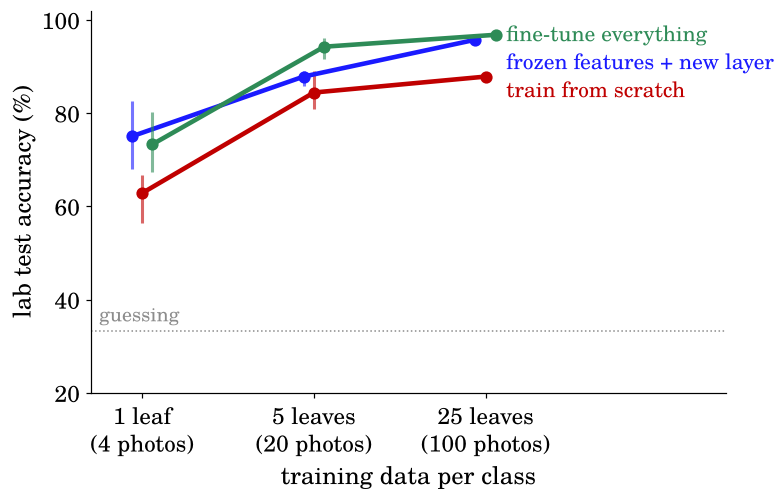

In [6]:
NS = [1, 5, 25]
fig, ax = plt.subplots(figsize=(7.4, 4.8))
arts = []
style = {'frozen': (BLUE, 'frozen features + new layer'), 'finetune': (GREEN, 'fine-tune everything'),
         'scratch': (RED, 'train from scratch')}
# end labels: start at the final mean, then push apart (at least 6 points) so they never overlap
label_y = {mt: summary(mt, NS[-1])[0] for mt in style}
prev = None
for mt in sorted(label_y, key=label_y.get, reverse=True):
    if prev is not None:
        label_y[mt] = min(label_y[mt], label_y[prev] - 6)
    prev = mt
for method in ['scratch', 'frozen', 'finetune']:
    c, lbl = style[method]
    m_ = np.array([summary(method, n) for n in NS])
    xs = np.arange(len(NS)) + {'frozen': -0.06, 'finetune': 0.06, 'scratch': 0}[method]
    l, = ax.plot(xs, m_[:, 0], color=c, lw=3, marker='o', ms=7)
    e = ax.vlines(xs, m_[:, 1], m_[:, 2], color=c, lw=2, alpha=0.6)
    t = ax.text(2.12, label_y[method], lbl, color=c, va='center', fontsize=14)
    arts.append([l, e, t])
ax.axhline(100 / 3, color=GREY, lw=1, ls=':'); g = ax.text(-0.25, 100 / 3 + 2, 'guessing', color=GREY, fontsize=13)
ax.set_xticks(range(len(NS)), [f'{n} leaf\n({4 * n} photos)' if n == 1 else f'{n} leaves\n({4 * n} photos)' for n in NS])
ax.set_xlabel('training data per class'); ax.set_ylabel('lab test accuracy (%)')
ax.set_ylim(20, 102); ax.set_xlim(-0.3, 3.4)
fig.tight_layout()
save_layers(fig, 'fig_size', [arts[0] + [g], arts[1], arts[2]])
plt.show()

## Part 3 · From the lab to the field

The models trained on 25 lab leaves per class are tested on field photos: does the model name the right disease (early vs late blight)? Then we add 20 field photos per disease to the training data and test on the other 182 field photos. Finally, how well can we do with field photos alone (no lab photos)?

In [7]:
R.setdefault('field_runs', {})
idx25 = train_indices(25, 0)
for method in ['frozen', 'finetune']:
    key = f'{method}+field'
    if key in R['field_runs'] and CLASS_MODE: continue
    t0 = time.time()
    if method == 'frozen':
        Xtr = torch.cat([Fl[idx25], Ff[field_train]]); ytr = torch.tensor(np.concatenate([y_lab[idx25], y_field[field_train]]))
        pred = train_head(Xtr, ytr)
        res = scores(pred(Fl[test_idx]), pred(Ff[field_test]))
    else:
        m = resnet18(True)
        pred = train_cnn(m, idx25, idx_field=field_train, steps=120, lr=0.01)
        res = scores(pred(LAB182[test_idx]), pred(FIELD182[field_test]))
    res['seconds'] = time.time() - t0
    R['field_runs'][key] = res; store()
    print(f'{key:16s} lab {res["lab"]:.1%}  field {res["field"]:.1%}  ({res["seconds"]:.0f}s)')

rows = [('scratch', 'scratch|25|0'), ('frozen', 'frozen|25|0'), ('fine-tune', 'finetune|25|0')]
for name, key in rows:
    r = R['size_runs'][key]
    print(f'{name:10s} lab {r["lab"]:.1%}   field {r["field"]:.1%}   (field photos called "healthy": {r["field_said_healthy"]:.0%})')
for key, r in R['field_runs'].items():
    print(f'{key:16s} lab {r["lab"]:.1%}   field {r["field"]:.1%}')

# Field photos only (no lab photos): frozen features with 5-fold cross-validation (3 repeats),
# and fine-tuning on 60 field photos per disease (two random splits), tested on the remaining field photos
yf2 = torch.tensor(y_field)
if not (CLASS_MODE and 'field_only' in R):
    fo = {}
    accs = []
    for rep in range(3):
        perm = np.random.default_rng(rep).permutation(len(field)); folds = np.array_split(perm, 5)
        for k in range(5):
            te = folds[k]; tr = np.concatenate([folds[j] for j in range(5) if j != k])
            pred = train_head(Ff[tr], yf2[tr], seed=rep)
            accs.append(float(((pred(Ff[te])[:, 1:].argmax(1) + 1) == yf2[te]).float().mean()))
    fo['frozen_cv'] = float(np.mean(accs))
    for split in (0, 1):
        g = np.random.default_rng(split); tr, te = [], []
        for c in (1, 2):
            ids = [i for i in range(len(field)) if y_field[i] == c]; g.shuffle(ids); tr += ids[:60]; te += ids[60:]
        torch.manual_seed(split); m = resnet18(True); gen = torch.Generator().manual_seed(split)
        opt = torch.optim.SGD(m.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4)
        sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=0.01, total_steps=100, pct_start=0.15)
        m.train()
        for _ in range(100):
            b = torch.tensor(tr)[torch.randint(0, len(tr), (16,), generator=gen)]
            xb = torch.stack([augment(x) for x in FIELD182[b]])
            loss = F.cross_entropy(m(to_input(xb)), yf2[b]); opt.zero_grad(); loss.backward(); opt.step(); sch.step()
        o = features(m, FIELD182[te], 160)
        fo[f'finetune_split{split}'] = float(((o[:, 1:].argmax(1) + 1) == yf2[te]).float().mean())
    R['field_only'] = fo; store()
print('field photos only:', {k: f'{v:.1%}' for k, v in R['field_only'].items()})

# Where do the field photos go? Predictions of the frozen model (25 lab leaves, seed 0)
pred = train_head(Fl[idx25], torch.tensor(y_lab[idx25]), seed=0)
pf = pred(Ff).argmax(1).numpy()
conf = {NICE[CLASSES[t]]: {NICE[CLASSES[p_]]: int(((y_field == t) & (pf == p_)).sum()) for p_ in range(3)} for t in (1, 2)}
R['field_confusion_frozen'] = conf; store()
print('frozen model, field photos (rows = true disease, columns = prediction):', conf)

scratch    lab 87.8%   field 52.7%   (field photos called "healthy": 29%)
frozen     lab 96.2%   field 52.7%   (field photos called "healthy": 9%)
fine-tune  lab 96.8%   field 53.8%   (field photos called "healthy": 5%)
frozen+field     lab 94.9%   field 54.9%
finetune+field   lab 99.4%   field 56.0%
field photos only: {'frozen_cv': '57.5%', 'finetune_split0': '66.7%', 'finetune_split1': '52.0%'}
frozen model, field photos (rows = true disease, columns = prediction): {'early blight': {'healthy': 8, 'early blight': 55, 'late blight': 54}, 'late blight': {'healthy': 12, 'early blight': 41, 'late blight': 52}}


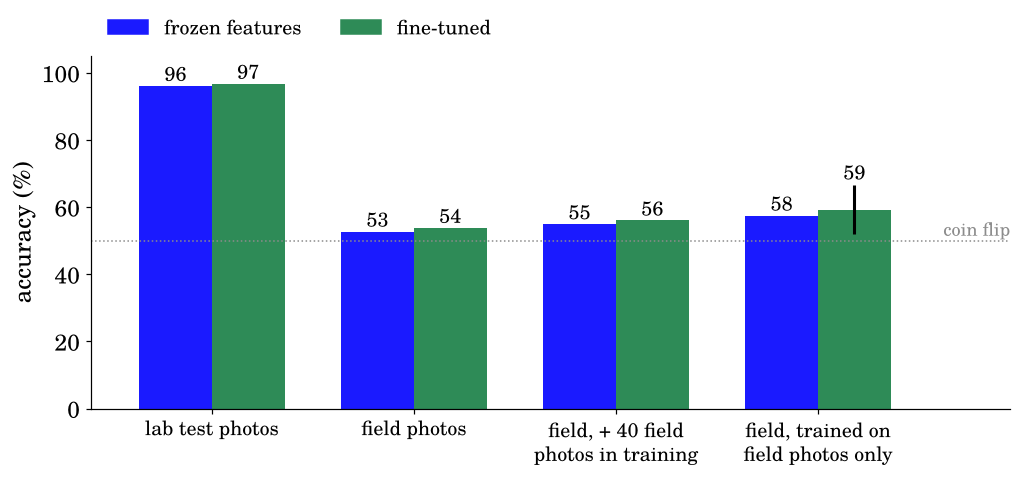

In [8]:
fo = R['field_only']
cats = ['lab test photos', 'field photos', 'field, + 40 field\nphotos in training', 'field, trained on\nfield photos only']
frz = [R['size_runs']['frozen|25|0']['lab'], R['size_runs']['frozen|25|0']['field'], R['field_runs']['frozen+field']['field'], fo['frozen_cv']]
ftv = [R['size_runs']['finetune|25|0']['lab'], R['size_runs']['finetune|25|0']['field'], R['field_runs']['finetune+field']['field'],
       np.mean([fo['finetune_split0'], fo['finetune_split1']])]
ftr = (min(fo['finetune_split0'], fo['finetune_split1']), max(fo['finetune_split0'], fo['finetune_split1']))
fig, ax = plt.subplots(figsize=(9.6, 4.6))
x = np.arange(4); w = 0.36
arts = [[], [], [], []]
for k in range(4):
    b1 = ax.bar(k - w / 2, 100 * frz[k], w, color=BLUE); t1 = ax.text(k - w / 2, 100 * frz[k] + 1.5, f"{100 * frz[k]:.0f}", ha='center', fontsize=13)
    b2 = ax.bar(k + w / 2, 100 * ftv[k], w, color=GREEN); t2 = ax.text(k + w / 2, 100 * ftv[k] + (9 if k == 3 else 1.5), f"{100 * ftv[k]:.0f}", ha='center', fontsize=13)
    arts[k] += [*b1, t1, *b2, t2]
er = ax.vlines(3 + w / 2, 100 * ftr[0], 100 * ftr[1], color='black', lw=2); arts[3].append(er)
cf = ax.axhline(50, color=GREY, lw=1, ls=':'); ct = ax.text(3.62, 51.5, 'coin flip', color=GREY, fontsize=12)
arts[1] += [cf, ct]
ax.set_xticks(x, cats, fontsize=13); ax.set_ylabel('accuracy (%)'); ax.set_ylim(0, 105); ax.set_xlim(-0.6, 3.95)
from matplotlib.patches import Patch
L = ax.legend(handles=[Patch(color=BLUE, label='frozen features'), Patch(color=GREEN, label='fine-tuned')],
              loc='lower left', bbox_to_anchor=(0, 1.0), frameon=False, fontsize=13, ncol=2)
arts[0].append(L)
fig.tight_layout()
save_layers(fig, 'fig_shift', arts)
plt.show()
plt.show()

## Part 4 · Choosing a backbone (and where the 1×1 convolutions are)

Four ImageNet backbones from torchvision, used as frozen feature extractors at the standard 224×224 size. For each: parameters, multiply-adds per photo (split by kind of convolution), CPU time per photo, and the accuracy of a new last layer trained on 5 leaves per class (seeds 0–2).

In [9]:
BACKBONES = {
    'ResNet-18': (models.resnet18, models.ResNet18_Weights.IMAGENET1K_V1, 'fc'),
    'ResNet-50': (models.resnet50, models.ResNet50_Weights.IMAGENET1K_V2, 'fc'),
    'MobileNetV3-L': (models.mobilenet_v3_large, models.MobileNet_V3_Large_Weights.IMAGENET1K_V2, 'classifier'),
    'EfficientNet-B0': (models.efficientnet_b0, models.EfficientNet_B0_Weights.IMAGENET1K_V1, 'classifier'),
}

def mac_split(m, size=224):
    """Multiply-adds of every convolution and linear layer, grouped by kind."""
    split = {'1x1 conv': 0, 'depthwise conv': 0, 'regular conv (3x3 and larger)': 0, 'fully connected': 0}
    def hook(mod, inp, out):
        if isinstance(mod, nn.Conv2d):
            k = mod.kernel_size[0] * mod.kernel_size[1]
            macs = out.numel() * (mod.in_channels // mod.groups) * k
            if mod.groups > 1 and mod.groups == mod.in_channels: split['depthwise conv'] += macs
            elif k == 1: split['1x1 conv'] += macs
            else: split['regular conv (3x3 and larger)'] += macs
        elif isinstance(mod, nn.Linear):
            split['fully connected'] += mod.in_features * mod.out_features
    hs = [mm.register_forward_hook(hook) for mm in m.modules() if isinstance(mm, (nn.Conv2d, nn.Linear))]
    with torch.no_grad(): m.eval()(torch.zeros(1, 3, size, size))
    for h in hs: h.remove()
    return split

R.setdefault('backbones', {})
need = [n for n in BACKBONES if not (CLASS_MODE and n in R['backbones'])]
if need:
    LAB256, FIELD256 = load_all(lab, 256), load_all(field, 256)
for name in BACKBONES:
    if name not in need: continue
    ctor, weights, head = BACKBONES[name]
    m = ctor(weights=weights).eval()
    info = {'params': sum(p.numel() for p in m.parameters()), 'macs': mac_split(m),
            'imagenet_top1': weights.meta['_metrics']['ImageNet-1K']['acc@1']}
    setattr(m, head, nn.Identity())                         # drop the 1000-class head: m(x) = features
    x1 = to_input(center(LAB256[:1], 224))
    with torch.no_grad():
        for _ in range(3): m(x1)
        t0 = time.time()
        for _ in range(20): m(x1)
    info['ms_per_photo'] = 1000 * (time.time() - t0) / 20
    t0 = time.time(); fl, ff = features(m, LAB256, 224), features(m, FIELD256, 224); info['feature_seconds'] = time.time() - t0
    accs = []
    for s in range(3):
        idx = train_indices(5, s); pred = train_head(fl[idx], torch.tensor(y_lab[idx]), seed=s)
        accs.append(scores(pred(fl[test_idx]), pred(ff[field_test])))
    info['lab_5leaves'] = float(np.mean([a['lab'] for a in accs])); info['field_5leaves'] = float(np.mean([a['field'] for a in accs]))
    R['backbones'][name] = info; store()

print(f"{'backbone':16s} {'params':>8s} {'GMACs':>6s} {'1x1 share':>9s} {'ms/photo':>9s} {'ImageNet':>9s} {'lab (5 leaves)':>15s} {'field':>6s}")
for name, i in R['backbones'].items():
    tot = sum(i['macs'].values())
    print(f"{name:16s} {i['params'] / 1e6:7.1f}M {tot / 1e9:6.2f} {i['macs']['1x1 conv'] / tot:9.0%} {i['ms_per_photo']:9.0f} "
          f"{i['imagenet_top1']:8.1f}% {100 * i['lab_5leaves']:14.1f}% {100 * i['field_5leaves']:5.1f}%")

backbone           params  GMACs 1x1 share  ms/photo  ImageNet  lab (5 leaves)  field
ResNet-18           11.7M   1.81        1%        25     69.8%           95.5%  62.6%
ResNet-50           25.6M   4.09       52%        63     80.9%           81.8%  53.7%
MobileNetV3-L        5.5M   0.22       88%        14     75.3%           92.5%  53.7%
EfficientNet-B0      5.3M   0.39       88%        17     77.7%           96.2%  55.9%


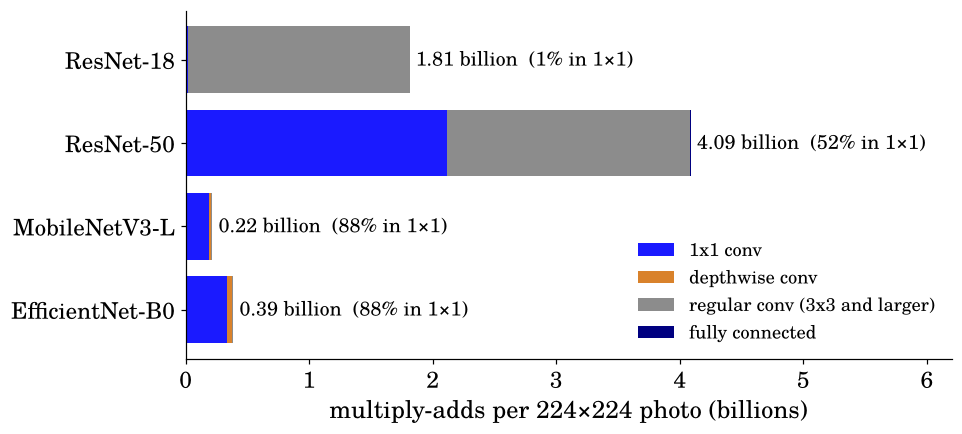

In [10]:
names_ = list(R['backbones'])
kinds = ['1x1 conv', 'depthwise conv', 'regular conv (3x3 and larger)', 'fully connected']
kcol = {'1x1 conv': BLUE, 'depthwise conv': ORANGE, 'regular conv (3x3 and larger)': GREY, 'fully connected': NAVY}
fig, ax = plt.subplots(figsize=(9.0, 4.2))
left = np.zeros(len(names_))
for k in kinds:
    v = np.array([R['backbones'][n]['macs'][k] / 1e9 for n in names_])
    ax.barh(names_, v, left=left, color=kcol[k], label=k)
    left += v
for i, n in enumerate(names_):
    tot = sum(R['backbones'][n]['macs'].values())
    ax.text(left[i] + 0.05, i, f"{tot / 1e9:.2f} billion  ({R['backbones'][n]['macs']['1x1 conv'] / tot:.0%} in 1×1)", va='center', fontsize=13)
ax.invert_yaxis(); ax.set_xlabel('multiply-adds per 224×224 photo (billions)'); ax.set_xlim(0, 6.2)
ax.legend(loc='lower right', frameon=False, fontsize=12)
fig.tight_layout(); save(fig, 'fig_macs'); plt.show()

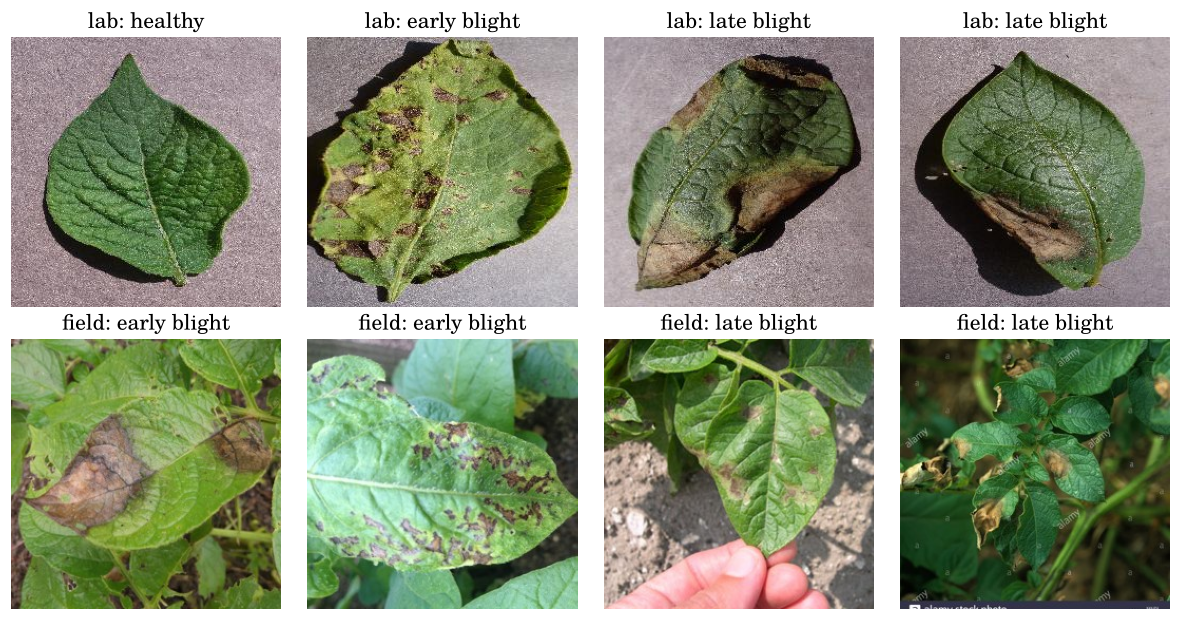

In [11]:
# photos for the slides: four lab and four field examples
import random as _r
_r.seed(3)
pick = [('lab', 'healthy'), ('lab', 'early_blight'), ('lab', 'late_blight'), ('field', 'early_blight'), ('field', 'late_blight')]
fig, axs = plt.subplots(2, 4, figsize=(11, 5.8))
for row, src, rows_ in ((0, 'lab', lab), (1, 'field', field)):
    cand = [r for r in rows_ if r['label'] != 'healthy'] if src == 'field' else rows_
    labels = ['healthy', 'early_blight', 'late_blight', 'late_blight'] if src == 'lab' else ['early_blight', 'early_blight', 'late_blight', 'late_blight']
    for col, lbl in enumerate(labels):
        r = _r.choice([x for x in cand if x['label'] == lbl])
        im = Image.open(os.path.join(DATA, r['path'])).convert('RGB'); w, h = im.size; s = min(w, h)
        im = im.crop(((w - s) // 2, (h - s) // 2, (w - s) // 2 + s, (h - s) // 2 + s))
        axs[row, col].imshow(im); axs[row, col].set_xticks([]); axs[row, col].set_yticks([])
        axs[row, col].set_title(f'{src}: {NICE[lbl]}', fontsize=14)
        for sp in axs[row, col].spines.values(): sp.set_visible(False)
fig.tight_layout(); save(fig, 'fig_samples'); plt.show()

## Things to try (with or without an AI assistant)

1. Split the lab photos **by photo** instead of by leaf (four photos of the same leaf can land in train and test). How much does the test accuracy go up? Is that real?
2. Fine-tune only the last stage (`layer4`) and the new layer, keeping the rest frozen. Where does it land between "frozen" and "fine-tune everything"?
3. Freeze the backbone but leave it in `train()` mode during training. What happens to the batch-norm running averages (Feb 3), and to the accuracy?
4. Collect 10 photos of potato leaves yourself (or any plant) and test the two saved models (25 leaves per class). Which one survives your photos best? To load one:
   `m = resnet18(pretrained=False); m.load_state_dict({k: v.float() for k, v in torch.load(os.path.join(RESULTS, 'finetune_25leaves.pt')).items()}); m.eval()`